# Lab 3: Keras

## Exercise 3.1: German Credit Numeric example in Keras

### Sequential model

In [ ]:
import keras
from keras import layers

import tensorflow_datasets as tfds
import tensorflow as tf

# Cargamos el conjunto de datos
ds = tfds.load('german_credit_numeric', split='train',as_supervised=True)

tamano_lote = 1000

elems = ds.batch(tamano_lote)
lote_entrenamiento = None
for elem in elems:
    lote_entrenamiento = elem
    break

In [2]:
#TODO - indicar la función de perdida y el algoritmo de optimización
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(learning_rate=0.001)

#Definimos la métrica Precision 
metrica = tf.keras.metrics.Precision()

In [3]:
tamano_entrada = 24
h0_size = 5
h1_size = 3

#TODO - define el modelo indicando un nombre 
model = keras.Sequential(name='german_credit_secuencial')

model.add(tf.keras.layers.InputLayer((tamano_entrada,)))
#TODO - incluye las 3 capas Dense al modelo 
model.add(layers.Dense(h0_size, activation='sigmoid', name='hidden_0'))
model.add(layers.Dense(h1_size, activation='sigmoid', name='hidden_1'))
model.add(layers.Dense(1, activation='sigmoid', name='output'))

#Se construye el modelo y se muestra
model.build()
print(model.summary())

Model: "german_credit_secuencial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_0 (Dense)                │ (None, 5)              │           125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 3)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147 (588.00 B)

 Trainable params: 147 (588.00 B)

 Non-trainable params: 0 (0.00 B)

None


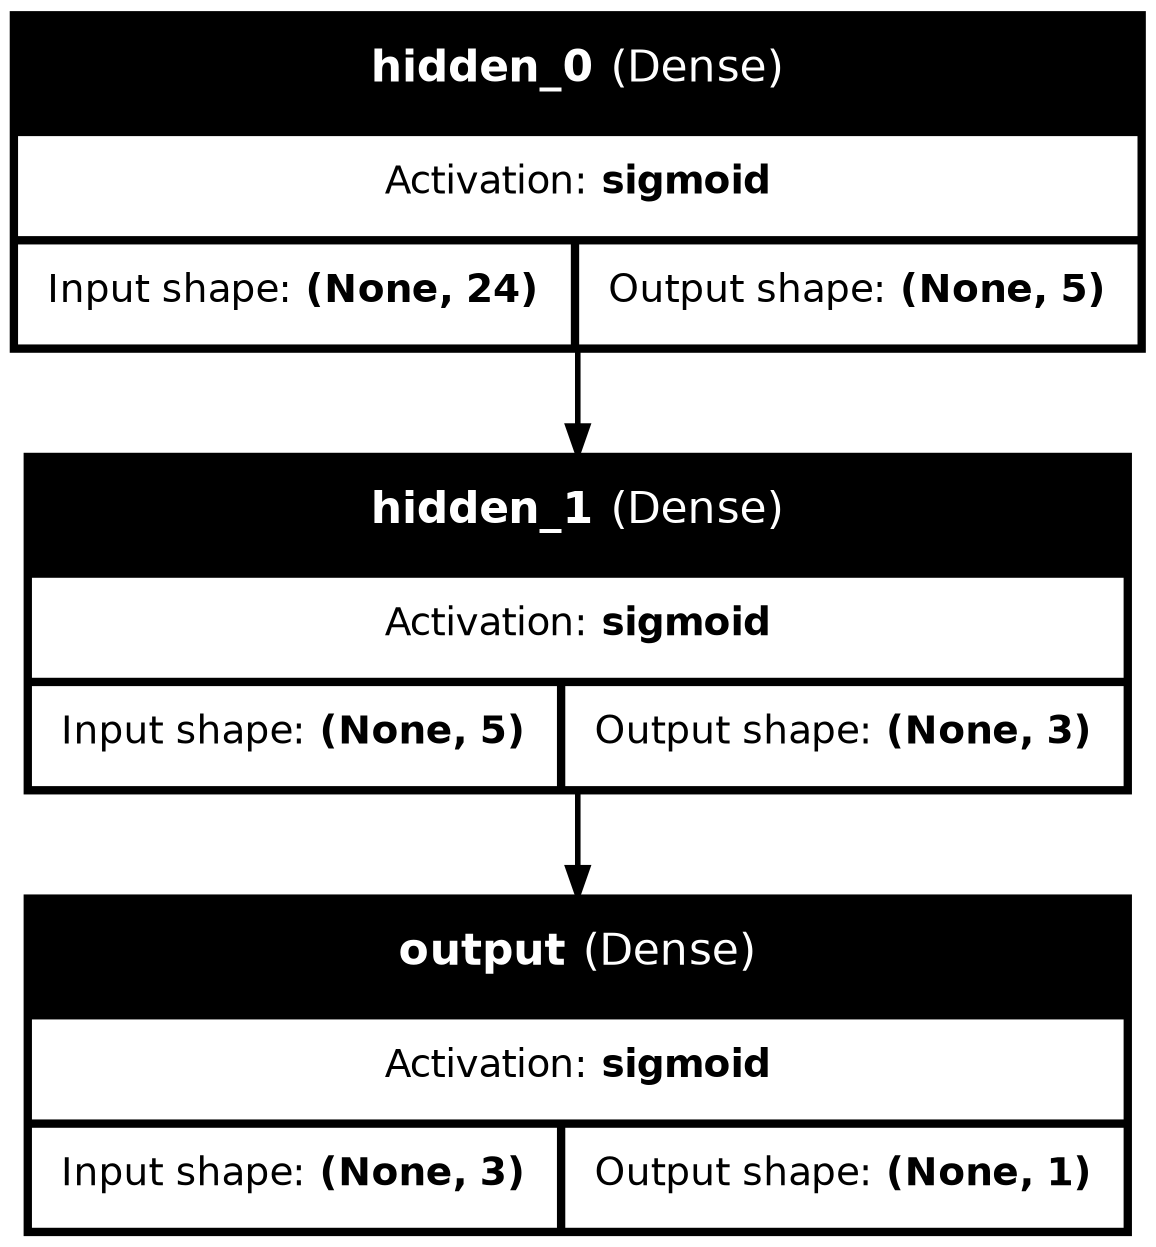

In [4]:
tf.keras.utils.plot_model(model, 'my_first_model.png', show_shapes=True, show_layer_names=True, show_layer_activations=True)

In [5]:
#TODO - indicar los parametros del método compile
model.compile(loss=fn_perdida,
              optimizer=optimizador,
              metrics=[metrica])

In [6]:
num_epochs =  50
#TODO - entrenar el modelo
history = model.fit(lote_entrenamiento[0], lote_entrenamiento[1],
                    epochs=num_epochs,
                    batch_size=32,
                    validation_split=0.2)
history.history

Epoch 1/50


I0000 00:00:1795007016.527178   99941 service.cc:155] XLA service 0x11be7890 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795007016.527213   99941 service.cc:171]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.9.0[576.80.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795007016.542700   99941 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


18/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8764 - precision: 0.0000e+00

I0000 00:00:1795007018.121202   99941 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.8652 - precision: 0.0000e+00 - val_loss: 0.8164 - val_precision: 0.0000e+00
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.8122 - precision: 0.0000e+00 - val_loss: 0.7754 - val_precision: 0.0000e+00
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.7688 - precision: 0.0000e+00 - val_loss: 0.7436 - val_precision: 0.0000e+00
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7331 - precision: 0.7451 - val_loss: 0.7174 - val_precision: 0.6226
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7035 - precision: 0.7347 - val_loss: 0.6960 - val_precision: 0.6824
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6796 - precision: 0.7332 - val_loss: 0.6786 - val_precision: 0.6719
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6609 - precision: 0.7224 - val_loss: 0.6653 - val_precision: 0.6789
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.6477 - precision: 0.7229 - va

{'loss': [0.8652170300483704,
  0.8121670484542847,
  0.7687808871269226,
  0.7331364154815674,
  0.7034971714019775,
  0.6795526146888733,
  0.6609218120574951,
  0.6476647853851318,
  0.6378097534179688,
  0.6299688220024109,
  0.6237791776657104,
  0.6188705563545227,
  0.6148478388786316,
  0.6114685535430908,
  0.608589768409729,
  0.606113076210022,
  0.6039667129516602,
  0.6020856499671936,
  0.6004172563552856,
  0.5989129543304443,
  0.5975318551063538,
  0.5962442755699158,
  0.5950269103050232,
  0.5938607454299927,
  0.5927435755729675,
  0.5916712284088135,
  0.5906188488006592,
  0.5895775556564331,
  0.5885196924209595,
  0.5874512791633606,
  0.5863538980484009,
  0.5852378606796265,
  0.584113359451294,
  0.5829635262489319,
  0.5817981958389282,
  0.5806102156639099,
  0.5793960094451904,
  0.5781496167182922,
  0.5768436193466187,
  0.5754751563072205,
  0.5740369558334351,
  0.5725077390670776,
  0.5709044933319092,
  0.569221556186676,
  0.5674800872802734,
  0.56

In [7]:
#TODO - llamar a evaluate, guardando el resultado
result = model.evaluate(lote_entrenamiento[0], lote_entrenamiento[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5671 - precision: 0.7083


In [8]:
# Mostramos el resultado obtenido
print(model.metrics_names)
print(result)

['loss', 'compile_metrics']
[0.5671267509460449, 0.708290696144104]


### Functional model

In [9]:
inputs = keras.Input(shape=(24,))
inputs.shape

(None, 24)

In [10]:
h0_size = 5
h1_size = 3
x = layers.Dense(h0_size, activation='sigmoid')(inputs)
#TODO - crear el resto de capas 
x = layers.Dense(h1_size, activation='sigmoid')(x)
outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

In [11]:
#TODO- definir el modelo 
model = keras.Model(inputs=inputs, outputs=outputs, name='german_credit_functional')

#TODO- mostrar un resumen del modelo
model.summary()

Model: "german_credit_functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147 (588.00 B)

 Trainable params: 147 (588.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
#TODO compilar el modelo
model.compile(loss=keras.losses.BinaryCrossentropy(),
              optimizer=keras.optimizers.Adam(learning_rate=0.001),
              metrics=[keras.metrics.Precision()])

#TODO determinar el numero de epochs
num_epochs = 50

#TODO - entrenar el modelo 
history = model.fit(lote_entrenamiento[0], lote_entrenamiento[1],
                    epochs=num_epochs,
                    batch_size=32,
                    validation_split=0.2)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.6197 - precision_1: 0.7075 - val_loss: 0.6408 - val_precision_1: 0.6700
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6147 - precision_1: 0.7075 - val_loss: 0.6388 - val_precision_1: 0.6700
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6110 - precision_1: 0.7075 - val_loss: 0.6382 - val_precision_1: 0.6700
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6087 - precision_1: 0.7075 - val_loss: 0.6381 - val_precision_1: 0.6700
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6065 - precision_1: 0.7075 - val_loss: 0.6387 - val_precision_1: 0.6700
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6024 - precision_1: 0.7075 - val_loss: 0.6401 - val_precision_1: 0.6700
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5986 - precision_1: 0.7075 - val_loss: 0.6390 - val_precision_1: 0.6700
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5960 - precisio

In [13]:
history.history

{'loss': [0.619695246219635,
  0.6147099137306213,
  0.6110144853591919,
  0.6086786985397339,
  0.6065009832382202,
  0.60239577293396,
  0.5985590219497681,
  0.5960473418235779,
  0.5942951440811157,
  0.5927557945251465,
  0.591329038143158,
  0.5899855494499207,
  0.5886968374252319,
  0.5874366164207458,
  0.5861908793449402,
  0.5849552750587463,
  0.5837259888648987,
  0.5824878215789795,
  0.581255316734314,
  0.5800116062164307,
  0.5787557363510132,
  0.5774871706962585,
  0.576196014881134,
  0.5748723745346069,
  0.5735234022140503,
  0.5721377730369568,
  0.5707110166549683,
  0.5692430734634399,
  0.5677120685577393,
  0.5661230683326721,
  0.5645063519477844,
  0.5628280639648438,
  0.561093807220459,
  0.5592947602272034,
  0.5574243664741516,
  0.5554929375648499,
  0.5534901022911072,
  0.5514206886291504,
  0.5492822527885437,
  0.5470792651176453,
  0.544815719127655,
  0.5424907207489014,
  0.5401099920272827,
  0.5376833081245422,
  0.5352263450622559,
  0.532747

In [14]:
#TODO - evaluar el modelo
result = model.evaluate(lote_entrenamiento[0], lote_entrenamiento[1])
print(model.metrics_names)
print(result)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5364 - precision_1: 0.7000
['loss', 'compile_metrics']
[0.5363569259643555, 0.699999988079071]


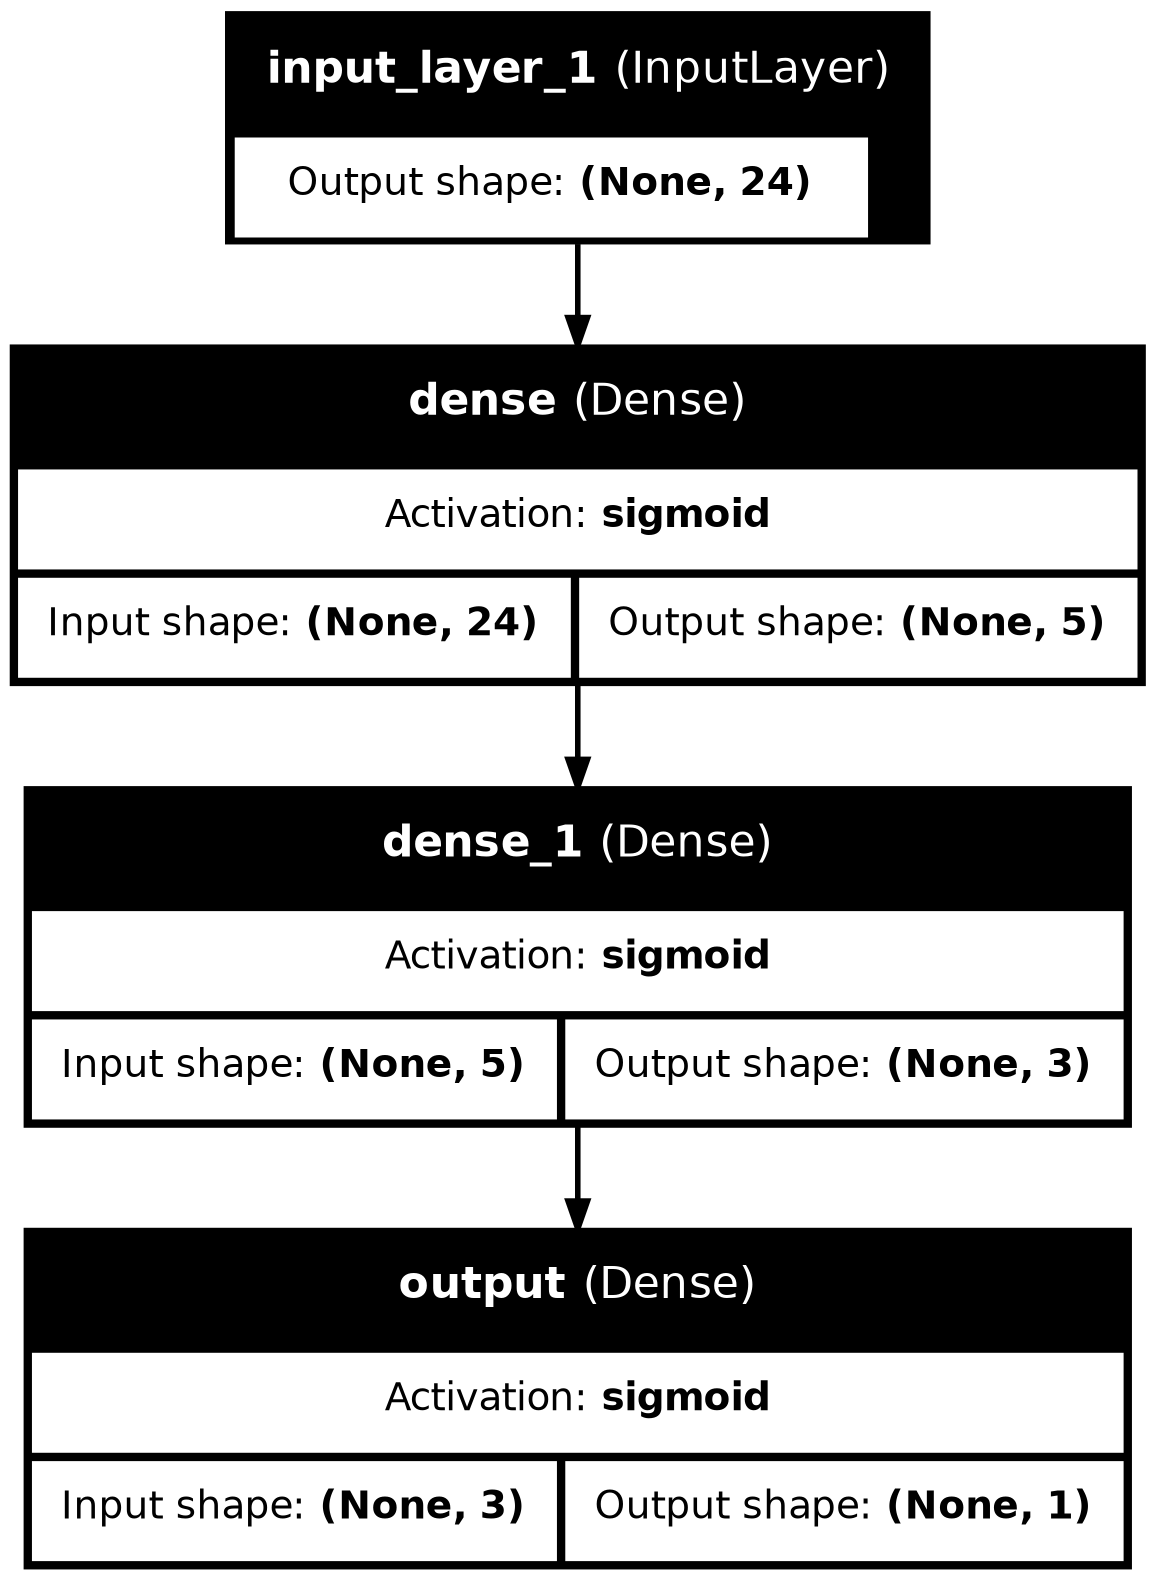

In [15]:
#TODO: muestra el gráfico del modelo
keras.utils.plot_model(model, 'functional_model.png',
                       show_shapes=True, show_layer_names=True,
                       show_layer_activations=True)